# Rutherford Scattering

In [408]:
import numpy as np
import matplotlib.pyplot as plt
import spinmob
import mcphysics
from scipy import optimize, constants
import seaborn as sns

In [409]:
plt.rcdefaults()
sns.set_theme(
    "paper",
    "ticks",
)
np.random.seed(42)

# Calibration

In [410]:
data = mcphysics.data.load_chn("2026-11-10_calibration.Chn")

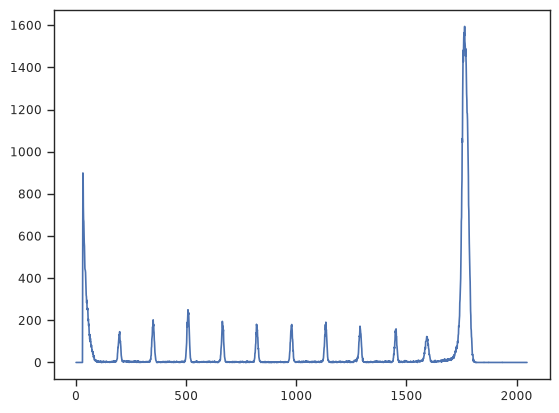

In [411]:
plt.plot(data[0], data[1])

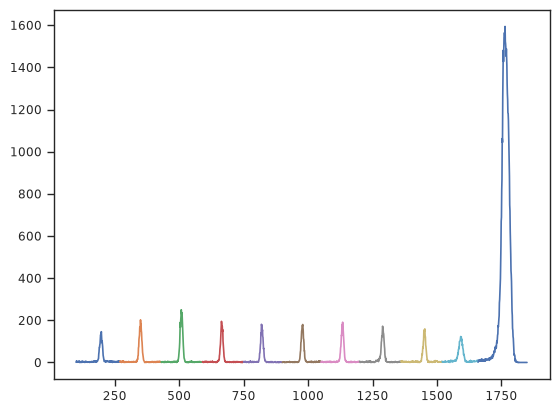

In [412]:
edges = [100, 270, 430, 590, 750, 900, 1050, 1200, 1360, 1520, 1660, 1850]

for i in range(len(edges) - 1):
    plt.plot(data[0][edges[i]:edges[i+1]], data[1][edges[i]:edges[i+1]])

0.1257474439654292
196.8276610339603 1.007875200440927


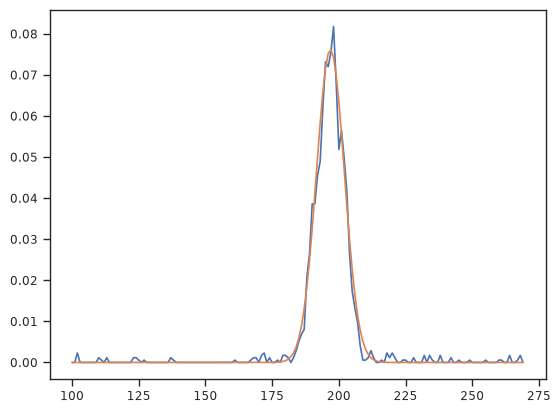

0.10591465748530057
349.85703658781773 1.005593314750167


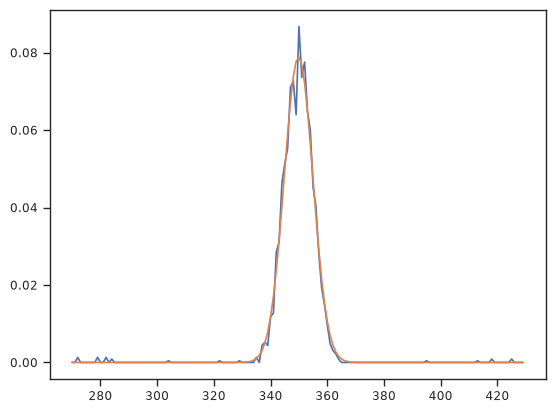

0.09033672353656955
508.66340960276125 1.0040720709288367


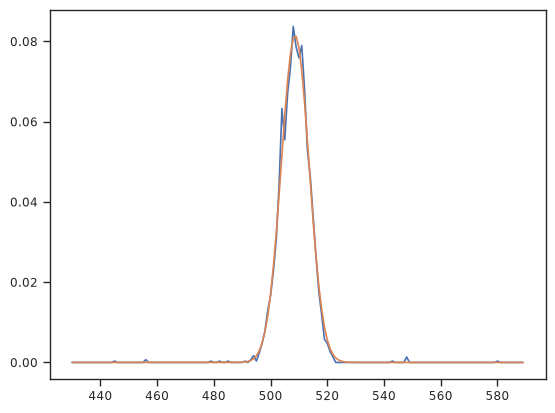

0.10040911543308265
665.2682969799123 1.0050283530637603


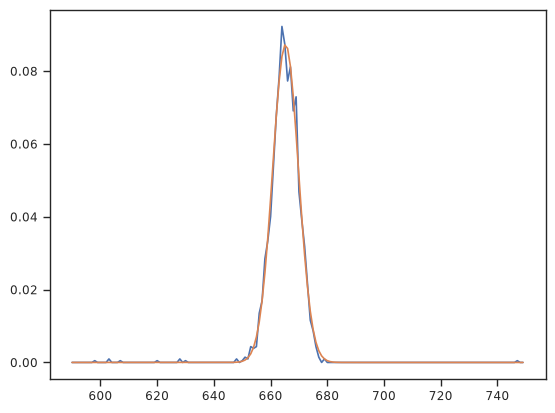

0.10580768166629345
820.6163279260127 1.00558205309144


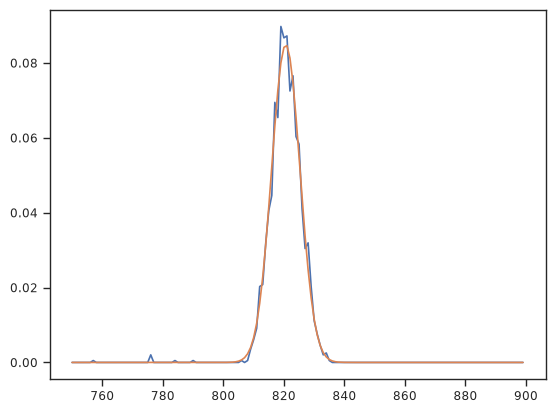

0.10452096323438993
978.034275532989 1.0054474783674405


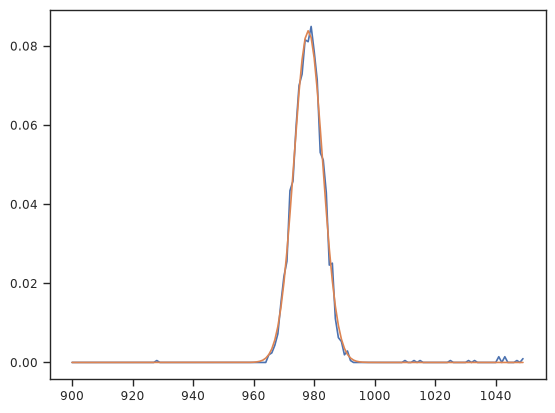

0.10630617270381308
1133.1581363313348 1.0056346266686191


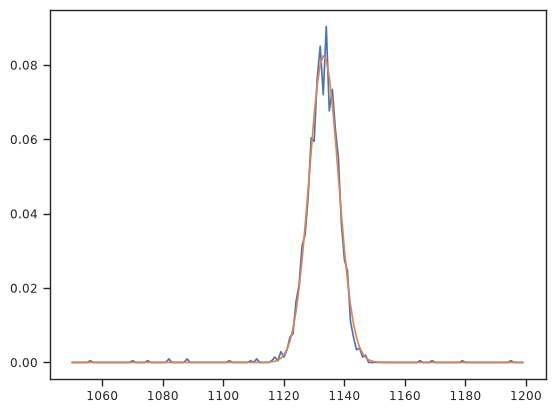

0.11494195322752929
1289.6471783807208 1.0065841507850994


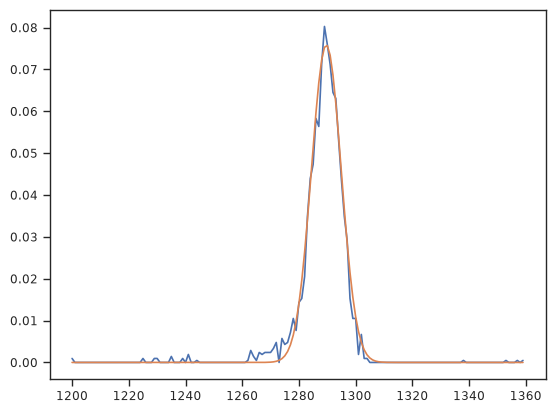

0.11481519476127067
1451.3373822465267 1.006569684099451


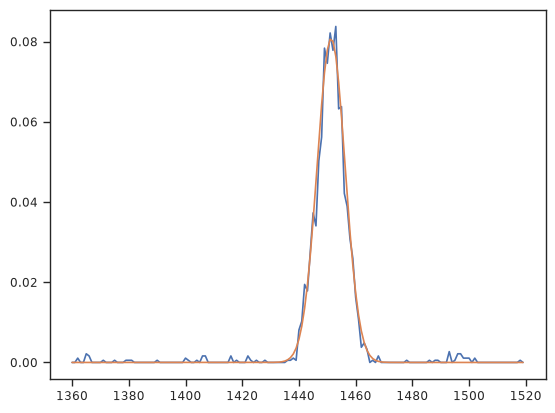

0.1641721739264581
1592.4090129775877 1.0133866501448197


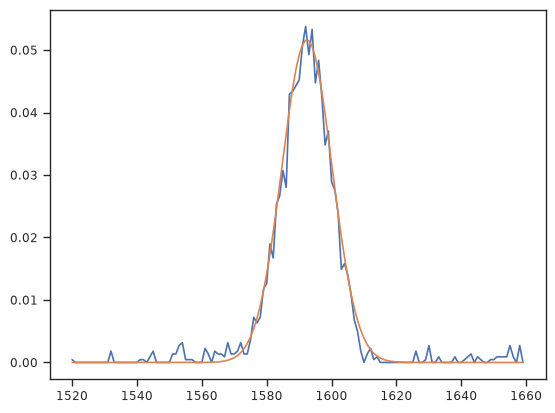

0.057629857054769536
1765.7239758320961 1.0016592237004325


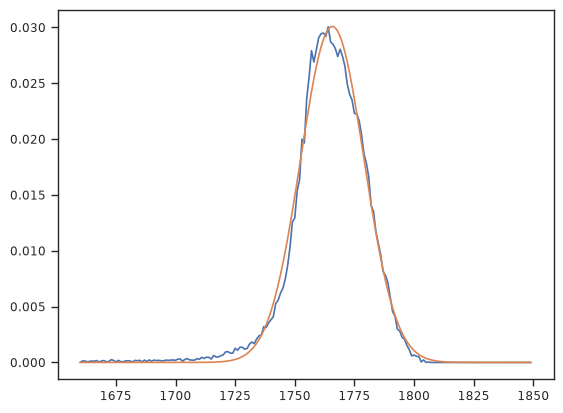

In [413]:
peaks = []
peak_uncertainties = []
model = lambda x, mu, sigma: np.pow(2 * np.pi * sigma**2, -1/2) * np.exp(-(x - mu)**2 / (2 * sigma**2))

for i in range(len(edges)-1):
    bins = data[0][edges[i]:edges[i+1]]
    counts = data[1][edges[i]:edges[i+1]]

    for j in range(len(counts)):
        if counts[j] <= 4:
            counts[j] = 0
        else:
            counts[j] -= 4

    area = np.sum(counts)
    n_counts = counts / area

    fit = optimize.curve_fit(
        model,
        bins,
        n_counts,
        p0=((1/2) * (edges[i] + edges[i+1]),  10.0)
    )
    peaks.append(fit[0][0])
    print(fit[0][1] / np.sqrt(area))
    uncertainty = np.sqrt(fit[0][1]**2 / area + 1)
    peak_uncertainties.append(uncertainty)
    print(fit[0][0], uncertainty)
    
    plt.plot(bins, n_counts)
    plt.plot(bins, model(bins, *fit[0]))
    plt.show()

peak_uncertainties = np.array(peak_uncertainties)
peaks = np.array(peaks)

In [414]:
base_energy = 5.57828 # MeV
base_uncertainty = 0.00012

dial_settings = np.array([0.48, 0.98, 1.48, 1.98, 2.48, 2.98, 3.48, 3.98, 4.48, 4.98, 5.48])
energies = base_energy * (1 / 5.48) * dial_settings

energy_uncertainties = []
for i in range(len(energies)):
    uncertainty = energies[i] * np.sqrt((base_uncertainty/base_energy)**2 + (0.01/5.48)**2 + (0.01/dial_settings[i])**2)
    energy_uncertainties.append(uncertainty)

energy_uncertainties = np.array(energy_uncertainties)
print(energy_uncertainties)


[0.01021832 0.01034086 0.0105441  0.0108235  0.01117335 0.01158727
 0.01205867 0.01258108 0.01314842 0.01375514 0.01439627]


<ErrorbarContainer object of 3 artists>

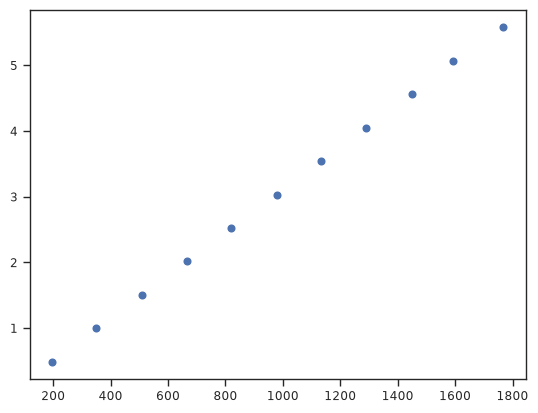

In [415]:
plt.errorbar(peaks, energies, yerr=energy_uncertainties, xerr=peak_uncertainties, fmt='o')

In [416]:
approx_slope = (energies[-1] - energies[0]) / (peaks[-1] - peaks[0])
uncertainties = np.sqrt((approx_slope * peak_uncertainties)**2 + energy_uncertainties**2)

In [417]:
linear_model = lambda x, a, b: a*x + b
calibration = optimize.curve_fit(
    linear_model,
    peaks,
    energies,
    sigma=uncertainties,
    absolute_sigma=True,
    p0=(approx_slope, 0)
)

errs = np.sqrt(np.diag(calibration[1]))
print(calibration[0][0], errs[0])
print(calibration[0][1], errs[1])

0.0032545079576142407 7.59146153090507e-06
-0.14752976238351884 0.007601611428029676


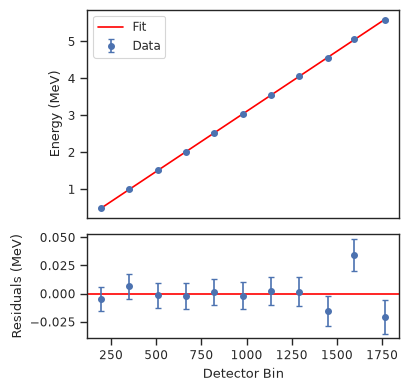

In [418]:
fig, ax = plt.subplots(2, 1, figsize=(4, 4), height_ratios=(2, 1))

space = np.linspace(np.min(peaks), np.max(peaks), 10)
vals = linear_model(space, *calibration[0])
ax[0].plot(space, vals, c="red", label="Fit")
ax[0].errorbar(peaks, energies, uncertainties, fmt='bo', label="Data", ms=4, capsize=2)
ax[0].legend()
ax[0].set_ylabel("Energy (MeV)")
ax[0].set_xticks([])

ax[1].set_ylabel("Residuals (MeV)")
ax[1].set_xlabel("Detector Bin")
ax[1].axhline(0, c="red")
residuals = energies - linear_model(peaks, *calibration[0])
ax[1].errorbar(peaks, residuals, uncertainties, fmt='bo', ms=4, capsize=2)

fig.tight_layout()
plt.savefig("calibration.svg")

In [419]:
chi2 = np.sum(residuals**2 / uncertainties**2)
red_chi2 = chi2 / (len(residuals - 2))
print(red_chi2)

0.8953328578272294


# Energy Loss in Foil

In [420]:
foil_data = mcphysics.data.load_chn("thicknesswgolffoil.Chn")
nofo_data = mcphysics.data.load_chn("thicknesswithoutgoldfoil.Chn")

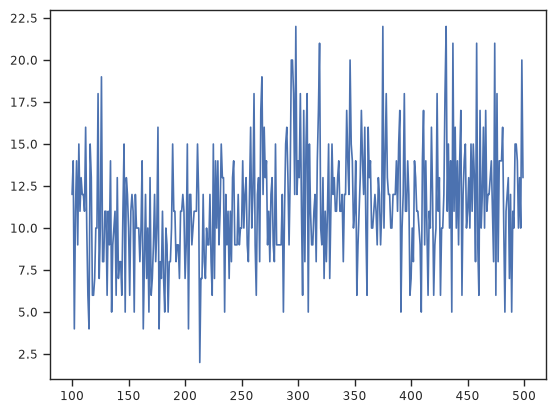

In [421]:
plt.plot(foil_data[0][100:500], foil_data[1][100:500])

In [422]:
foil_data[0] = foil_data[0][1200:1700]
foil_data[1] = foil_data[1][1200:1700]
nofo_data[0] = nofo_data[0][1200:1700]
nofo_data[1] = nofo_data[1][1200:1700]

for i in range(len(foil_data[0])):
    if foil_data[1][i] <= 25:
        foil_data[1][i] = 0
    else:
        foil_data[1][i] -= 25

    if nofo_data[1][i] <= 25:
        nofo_data[1][i] = 0
    else:
        nofo_data[1][i] -= 25

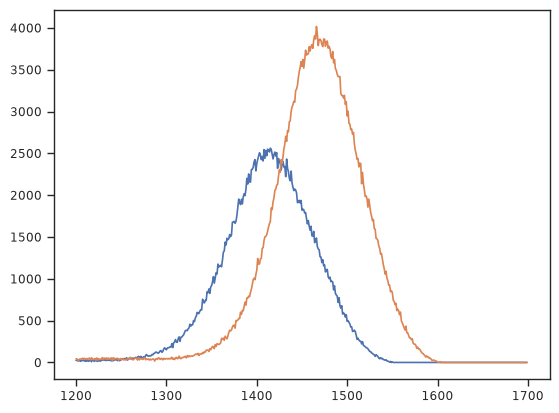

In [423]:
plt.plot(foil_data[0], foil_data[1])
plt.plot(nofo_data[0], nofo_data[1])

In [424]:
foil_area = np.sum(foil_data[1])
foil_normed = foil_data[1] / foil_area

nofo_area = np.sum(nofo_data[1])
nofo_normed = nofo_data[1] / nofo_area

foil_errs = np.sqrt(foil_data[1]) / foil_area
nofo_errs = np.sqrt(nofo_data[1]) / nofo_area

model = lambda x, mu, sigma: np.pow(2 * np.pi * sigma**2, -1/2) * np.exp(-(x - mu)**2 / (2 * sigma**2))

foil_fit = optimize.curve_fit(
    model,
    foil_data[0],
    foil_normed,
    p0=(1300, 10),
)

foil_mean = foil_fit[0][0]
foil_uncertainty = np.sqrt(np.diag(foil_fit[1]))[0]
print(foil_mean, foil_uncertainty)

nofo_fit = optimize.curve_fit(
    model,
    nofo_data[0],
    nofo_normed,
    p0=(1400, 10),
)

nofo_mean = nofo_fit[0][0]
nofo_uncertainty = np.sqrt(np.diag(nofo_fit[1]))[0]
print(nofo_mean, nofo_uncertainty)

1415.5609992361062 0.11265625453909293
1469.9436423408204 0.09457431429916101


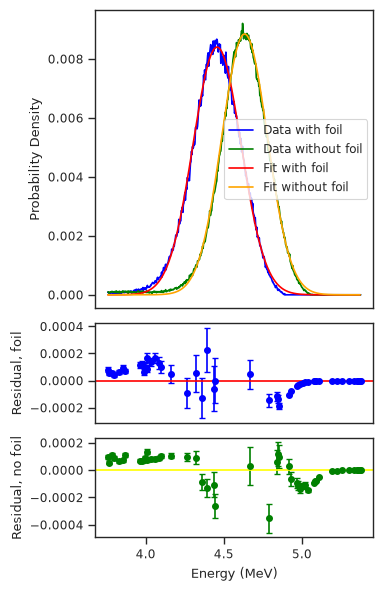

In [425]:
fig, ax = plt.subplots(3, 1, figsize=(4, 6), height_ratios=(3, 1, 1))

foil_energies = linear_model(foil_data[0], *calibration[0])
nofo_energies = linear_model(nofo_data[0], *calibration[0])
ax[0].plot(foil_energies, foil_normed, c="blue", label="Data with foil")
ax[0].plot(nofo_energies, nofo_normed, c="green", label="Data without foil")

space = np.arange(np.min(foil_data[0]), np.max(foil_data[0]))
foil_vals = model(space, *foil_fit[0])
nofo_vals = model(space, *nofo_fit[0])
space = linear_model(space, *calibration[0])
ax[0].plot(space, foil_vals, c="red", label="Fit with foil")
ax[0].plot(space, nofo_vals, c="orange", label="Fit without foil")

ax[0].legend()

ax[2].set_xlabel("Energy (MeV)")
ax[0].set_xticks([])
ax[1].set_xticks([])
ax[0].set_ylabel("Probability Density")

foil_errs = np.sqrt(foil_data[1]) / foil_area
nofo_errs = np.sqrt(nofo_data[1]) / nofo_area
foil_residuals = foil_normed - model(foil_data[0], *foil_fit[0])
nofo_residuals = nofo_normed - model(nofo_data[0], *nofo_fit[0])

indices = np.random.choice(len(foil_residuals), size=50, replace=False)
ax[1].errorbar(foil_energies[indices], foil_residuals[indices], foil_errs[indices], fmt='o', color="blue", ms=4, capsize=2)
ax[1].axhline(0, color="red")
ax[1].set_ylabel("Residual, foil")

ax[2].errorbar(nofo_energies[indices], nofo_residuals[indices], nofo_errs[indices], fmt='o', color="green", ms=4, capsize=2)
ax[2].axhline(0, color="yellow")
ax[2].set_ylabel("Residual, no foil")

fig.tight_layout()
plt.savefig("thickness.svg")

In [426]:
foil_energy = foil_fit[0][0] * calibration[0][0] + calibration[0][1]
foil_mean_uncertainty = foil_fit[0][1] / np.sqrt(foil_area)
foil_energy_uncertainty = foil_energy * np.sqrt((foil_mean_uncertainty / foil_fit[0][0])**2 + (errs[0] / calibration[0][0])**2)
foil_energy_uncertainty = np.sqrt(foil_energy_uncertainty**2 + errs[1]**2)
print(foil_energy, foil_energy_uncertainty)

nofo_energy = nofo_fit[0][0] * calibration[0][0] + calibration[0][1]
nofo_mean_uncertainty = nofo_fit[0][1] / np.sqrt(nofo_area)
nofo_energy_uncertainty = nofo_energy * np.sqrt((nofo_mean_uncertainty / nofo_fit[0][0])**2 + (errs[0] / calibration[0][0])**2)
nofo_energy_uncertainty = np.sqrt(nofo_energy_uncertainty**2 + errs[1]**2)
print(nofo_energy, nofo_energy_uncertainty)

dE = nofo_energy - foil_energy
dE_uncertainty = np.sqrt(foil_energy_uncertainty**2 + nofo_energy_uncertainty**2)
print(dE, dE_uncertainty)

4.459424774118755 0.012886538026109168
4.636413518859142 0.01322092277083111
0.17698874474038728 0.018462276707130087


In [444]:
I = 790 * 1.602176634e-19 # J
c = constants.c # m s^-1
Z = 2

rho = 19300 # kg m^-3
u = 0.19696657 # kg mol^-1
n = rho * constants.Avogadro / u * 79 # kg m^-3 * #atoms mol^-1 * kg^-1 mol * #electrons #atoms^-1 = #electrons m^-3

me = constants.electron_mass # kg
e = constants.elementary_charge # C
E0 = constants.epsilon_0 # C^2 s^2 kg^-1 m^-3

KE = 5.80496 * 1e6 * 1.602176634e-19 # J
m = 6.6446573450e-27 # kg
v = np.sqrt(2 * KE / m) # m s^-1
beta = v/c

dEdx = (
    -(4 * np.pi / (me * c**2))
    * (n * Z**2 / beta**2)
    * (e**2 / (4 * np.pi * E0)) ** 2
    * (np.log(2 * me * c**2 * beta**2 / ((1 - beta**2) * I)) - beta**2)
)

dEJ = dE * -1e6 * 1.602176634e-19
dx = dEJ / dEdx / np.sqrt(2)
dx_uncertainty = dE_uncertainty * 1e6 * 1.602176634e-19 / dEdx / np.sqrt(2)
print(dx, dx_uncertainty)

2.9417725913716837e-07 -3.068659516797041e-08
